[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alisherahmad/ml-regression-ames-housing/blob/main/House_Price_Regression_Ames.ipynb)

# Comparative Implementation of ML Regression Algorithms — Ames House Prices
**Dataset:** Ames Housing (Kaggle "House Prices: Advanced Regression Techniques", loaded from OpenML). It has 1,460 houses sold in Ames, Iowa (2006–2010), with 79 features each.
**Target:** `SalePrice` in US dollars.

**Algorithms:** Linear Regression, Decision Tree, Random Forest, Neural Network (MLP), XGBoost, K-Nearest Neighbors.

**Fair comparison:** all six models use the same features, the same target, the same 80:20 split (`random_state=42`), the same preprocessing and the same metrics (MAE, MSE, RMSE, R²).

In [ ]:
# Colab already has xgboost. If it is missing, run: !pip install xgboost
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings("ignore")
os.makedirs("images", exist_ok=True)
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

## 1. Load and explore the dataset

In [ ]:
data = fetch_openml(name="house_prices", version=1, as_frame=True)
df = data.frame.drop(columns=["Id"])
df["SalePrice"] = df["SalePrice"].astype(float)
print("Shape:", df.shape)
df[["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "YearBuilt", "Neighborhood", "SalePrice"]].head()

Shape: (1460, 80)


,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,Neighborhood,SalePrice
0,7,1710,2,856,2003,CollgCr,208500.0
1,6,1262,2,1262,1976,Veenker,181500.0
2,7,1786,2,920,2001,CollgCr,223500.0
3,7,1717,3,756,1915,Crawfor,140000.0
4,8,2198,3,1145,2000,NoRidge,250000.0


In [ ]:
print(df["SalePrice"].describe().round(0))
num_cols_all = df.select_dtypes(include="number").columns
corr = df[num_cols_all].corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)
print("\nTop 10 numeric features by correlation with SalePrice:\n", corr.head(10).round(3))

count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64

Top 10 numeric features by correlation with SalePrice:
 OverallQual     0.791
GrLivArea       0.709
GarageCars      0.640
GarageArea      0.623
TotalBsmtSF     0.614
1stFlrSF        0.606
FullBath        0.561
TotRmsAbvGrd    0.534
YearBuilt       0.523
YearRemodAdd    0.507
Name: SalePrice, dtype: float64


In [ ]:
missing = df.isnull().mean().sort_values(ascending=False)
missing = missing[missing > 0]
print(f"{len(missing)} columns have missing values:")
print((missing * 100).round(1).to_string())

19 columns have missing values:
PoolQC          99.5
MiscFeature     96.3
Alley           93.8
Fence           80.8
FireplaceQu     47.3
LotFrontage     17.7
GarageQual       5.5
GarageYrBlt      5.5
GarageType       5.5
GarageFinish     5.5
GarageCond       5.5
BsmtExposure     2.6
BsmtFinType2     2.6
BsmtCond         2.5
BsmtQual         2.5
BsmtFinType1     2.5
MasVnrArea       0.5
MasVnrType       0.5
Electrical       0.1


Most missing values mean *"the house does not have this"* (no pool, no alley, no garage), so they are not errors. Four columns are more than 80% empty and are dropped. The 4 houses with more than 4,000 sq ft of living area are also removed, as the dataset's author recommends.

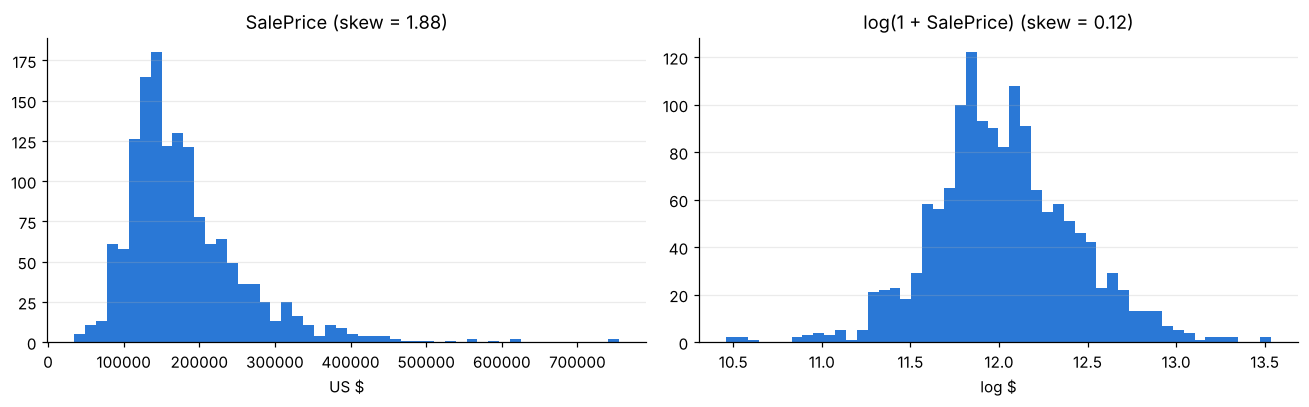

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(df["SalePrice"], bins=50, color="#2a78d6")
axes[0].set_title(f"SalePrice (skew = {df['SalePrice'].skew():.2f})"); axes[0].set_xlabel("US $")
axes[1].hist(np.log1p(df["SalePrice"]), bins=50, color="#2a78d6")
axes[1].set_title(f"log(1 + SalePrice) (skew = {np.log1p(df['SalePrice']).skew():.2f})"); axes[1].set_xlabel("log $")
for ax in axes: ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("images/target_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

SalePrice is right-skewed: a few very expensive houses stretch the scale. All models are trained on **log(1 + SalePrice)**, and their predictions are converted back to dollars before scoring. This way every metric is reported in real dollars.

## 2. Preprocessing: features, target, 80:20 split

In [ ]:
drop_cols = missing[missing > 0.80].index.tolist()
print("Dropped (>80% missing):", drop_cols)
df = df.drop(columns=drop_cols)

# The dataset's author (De Cock, 2011) recommends removing houses above 4,000 sq ft of living area:
# they are unusual sales (partial sales / very large houses) that distort every model.
outliers = df["GrLivArea"] > 4000
print("Removed outliers (GrLivArea > 4000):", int(outliers.sum()))
df = df[~outliers].reset_index(drop=True)

X = df.drop(columns="SalePrice")
y = df["SalePrice"]
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print(f"Numeric features: {len(num_cols)} | Categorical features: {len(cat_cols)}")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)

# Numeric features that are strongly right-skewed (|skew| > 0.75, decided on the training set) get a log(1+x) transform
skew = X_train[num_cols].skew().abs()
skewed_cols = [c for c in num_cols if skew[c] > 0.75 and X_train[c].min() >= 0]
other_num_cols = [c for c in num_cols if c not in skewed_cols]
print(f"Skewed numeric features log-transformed: {len(skewed_cols)}")

Dropped (>80% missing): ['PoolQC', 'MiscFeature', 'Alley', 'Fence']
Removed outliers (GrLivArea > 4000): 4
Numeric features: 36 | Categorical features: 39
Train: (1164, 75)  Test: (292, 75)
Skewed numeric features log-transformed: 19


**Preprocessing pipeline** (fitted on the training set only, so no test data leaks in):

| Column type | Step 1 | Step 2 |
| --- | --- | --- |
| Numeric (36) | Fill missing with the **median**; apply **log(1 + x)** to the 19 strongly skewed ones (e.g. LotArea, GrLivArea) | **StandardScaler** (only for Linear Regression, Neural Network, KNN) |
| Categorical (39) | Fill missing with the word **"None"** | **One-hot encode** (categories seen fewer than 10 times are grouped) |

Tree models (Decision Tree, Random Forest, XGBoost) don't need scaling, because they split on thresholds.

In [ ]:
def make_preprocessor(scale):
    scaler = [("scale", StandardScaler())] if scale else []
    skew_steps = [("impute", SimpleImputer(strategy="median")),
                  ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))] + scaler
    num_steps = [("impute", SimpleImputer(strategy="median"))] + scaler
    cat_steps = [("impute", SimpleImputer(strategy="constant", fill_value="None")),
                 ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False))]
    return ColumnTransformer([("skewed", Pipeline(skew_steps), skewed_cols),
                              ("num", Pipeline(num_steps), other_num_cols),
                              ("cat", Pipeline(cat_steps), cat_cols)])

def make_model(estimator, scale):
    # preprocessing -> model trained on log(1+price) -> predictions returned in dollars
    return Pipeline([("prep", make_preprocessor(scale)),
                     ("model", TransformedTargetRegressor(regressor=estimator, func=np.log1p, inverse_func=np.expm1))])

n_features = make_preprocessor(True).fit(X_train).transform(X_train[:5]).shape[1]
print("Number of model inputs after one-hot encoding:", n_features)

Number of model inputs after one-hot encoding: 241


## 3. Define the six models

In [ ]:
models = {
    "Linear Regression": (LinearRegression(), True),
    "Decision Tree":     (DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=SEED), False),
    "Random Forest":     (RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED), False),
    "Neural Network":    (MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", solver="adam", alpha=1.0,
                                       learning_rate_init=0.001, max_iter=2000, early_stopping=True,
                                       random_state=SEED), True),
    "XGBoost":           (XGBRegressor(n_estimators=1000, learning_rate=0.03, max_depth=4, subsample=0.8,
                                       colsample_bytree=0.6, random_state=SEED, n_jobs=-1), False),
    "KNN":               (KNeighborsRegressor(n_neighbors=7, weights="distance"), True),
}
# True/False = whether numeric features are standardised for that model

### Choosing k for KNN (5-fold CV on the training set only)

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
ks = [1, 3, 5, 7, 9, 11, 15, 21]
k_scores = [cross_val_score(make_model(KNeighborsRegressor(n_neighbors=k, weights="distance"), True),
                            X_train, y_train, cv=cv, scoring="r2").mean() for k in ks]
for k, s in zip(ks, k_scores):
    print(f"k={k:>2}  mean CV R2 = {s:.4f}")
best_k = ks[int(np.argmax(k_scores))]
print("Best k:", best_k)
models["KNN"] = (KNeighborsRegressor(n_neighbors=best_k, weights="distance"), True)

k= 1  mean CV R2 = 0.7476
k= 3  mean CV R2 = 0.8062
k= 5  mean CV R2 = 0.8068
k= 7  mean CV R2 = 0.8165
k= 9  mean CV R2 = 0.8131
k=11  mean CV R2 = 0.8069
k=15  mean CV R2 = 0.8078
k=21  mean CV R2 = 0.7994
Best k: 7


## 4. Train and evaluate every model on the same test set

In [ ]:
def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

results, preds, fitted = [], {}, {}
for name, (estimator, scale) in models.items():
    pipe = make_model(estimator, scale)
    t0 = time.time()
    pipe.fit(X_train, y_train)
    train_time = time.time() - t0
    y_pred = pipe.predict(X_test)
    preds[name], fitted[name] = y_pred, pipe
    row = {"Model": name, **evaluate(y_test, y_pred),
           "Train R2": r2_score(y_train, pipe.predict(X_train)), "Train time (s)": train_time}
    results.append(row)
    print(f"{name:<18} R2={row['R2']:.4f}  RMSE=${row['RMSE']:,.0f}  MAE=${row['MAE']:,.0f}")

Linear Regression  R2=0.9287  RMSE=$19,347  MAE=$13,787
Decision Tree      R2=0.7533  RMSE=$35,986  MAE=$26,410


Random Forest      R2=0.8810  RMSE=$24,988  MAE=$17,036


Neural Network     R2=0.8708  RMSE=$26,045  MAE=$17,238


XGBoost            R2=0.9160  RMSE=$20,999  MAE=$14,295
KNN                R2=0.8299  RMSE=$29,878  MAE=$20,054


## 5. Comparative performance table

In [ ]:
results_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1
results_df.style.format({"MAE": "${:,.0f}", "MSE": "{:.3e}", "RMSE": "${:,.0f}", "R2": "{:.4f}",
                         "Train R2": "{:.4f}", "Train time (s)": "{:.2f}"})

,Model,MAE,MSE,RMSE,R2,Train R2,Train time (s)
1,Linear Regression,"$13,787",3.743e+08,"$19,347",0.9287,0.9526,0.07
2,XGBoost,"$14,295",4.409e+08,"$20,999",0.9160,0.9959,0.70
3,Random Forest,"$17,036",6.244e+08,"$24,988",0.8810,0.9822,2.92
4,Neural Network,"$17,238",6.783e+08,"$26,045",0.8708,0.9447,1.35
5,KNN,"$20,054",8.927e+08,"$29,878",0.8299,1.0000,0.05
6,Decision Tree,"$26,410",1.295e+09,"$35,986",0.7533,0.9323,0.06


### Robustness check: 5-fold cross-validation R² on the training set

In [ ]:
cv_rows = []
for name, (estimator, scale) in models.items():
    s = cross_val_score(make_model(estimator, scale), X_train, y_train, cv=cv, scoring="r2")
    cv_rows.append({"Model": name, "CV R2 mean": s.mean(), "CV R2 std": s.std()})
cv_df = pd.DataFrame(cv_rows).sort_values("CV R2 mean", ascending=False).reset_index(drop=True)
cv_df.round(4)

,Model,CV R2 mean,CV R2 std
0,Linear Regression,0.9166,0.0091
1,XGBoost,0.9118,0.0196
2,Random Forest,0.8773,0.0189
3,KNN,0.8165,0.0249
4,Neural Network,0.7925,0.0873
5,Decision Tree,0.7798,0.0203


## 6. Visualisation: actual vs predicted

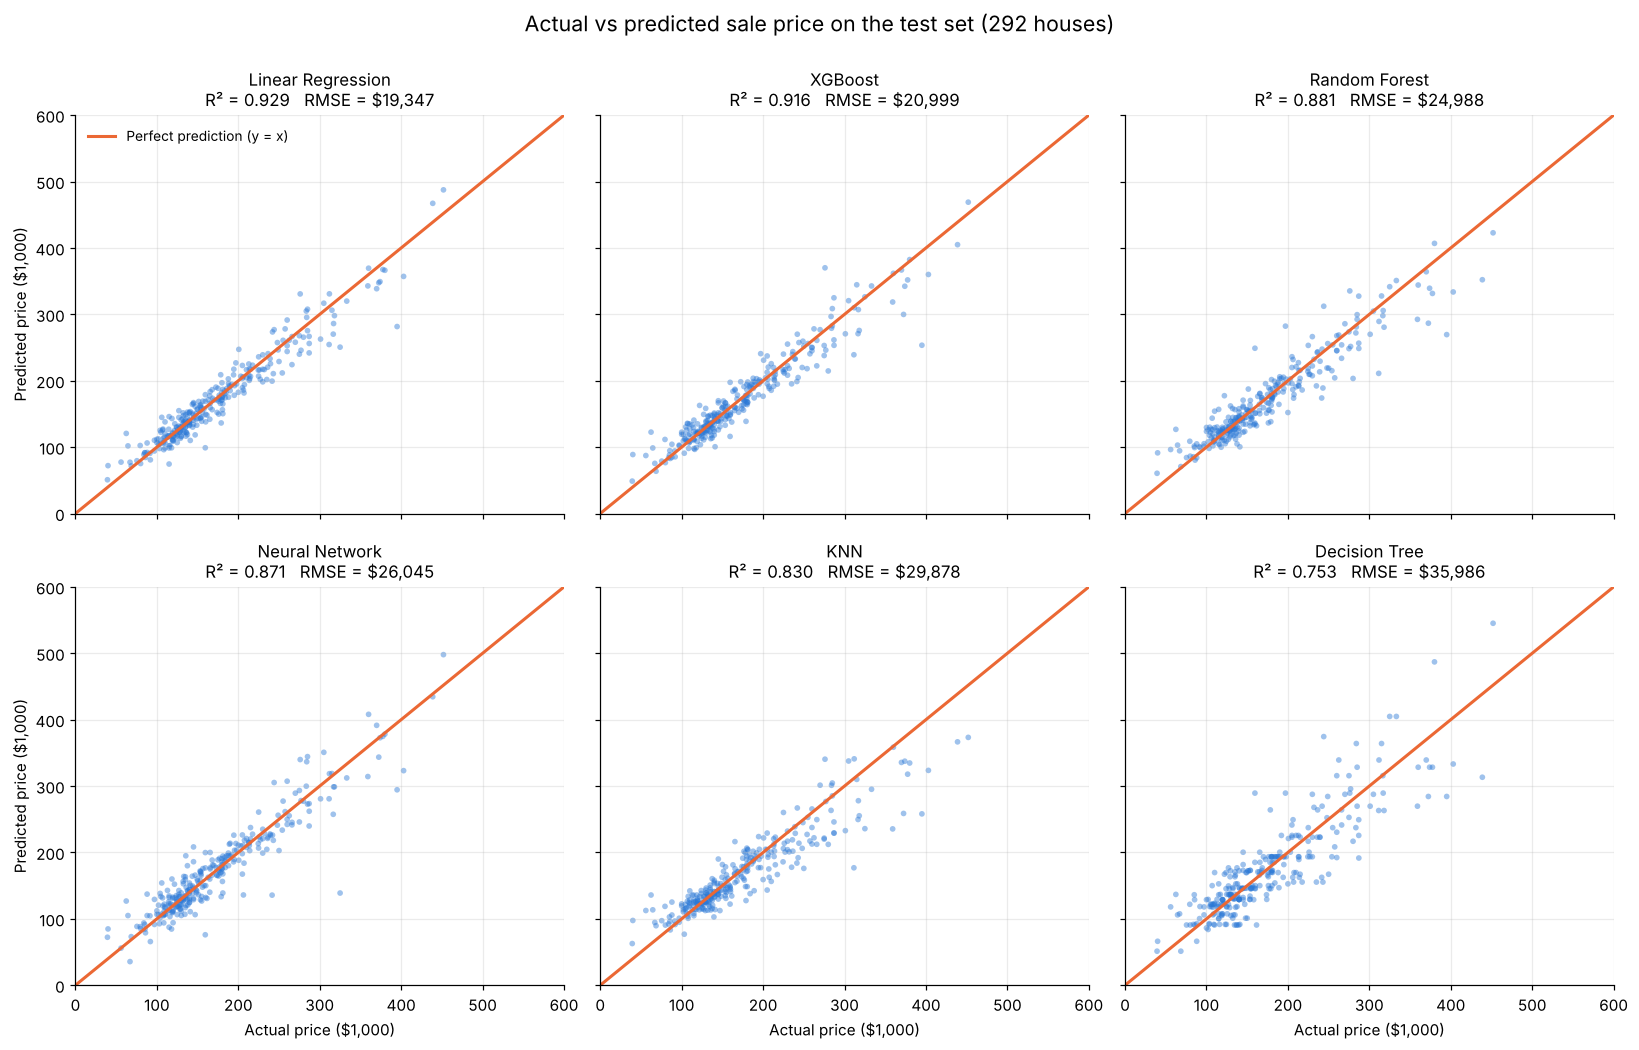

In [ ]:
order = results_df["Model"].tolist()
lim = (0, 600)
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), order):
    r = results_df.set_index("Model").loc[name]
    ax.scatter(y_test / 1000, preds[name] / 1000, s=14, alpha=0.45, color="#2a78d6", edgecolors="none")
    ax.plot(lim, lim, color="#eb6834", lw=2, label="Perfect prediction (y = x)")
    ax.set_title(f"{name}\nR² = {r['R2']:.3f}   RMSE = ${r['RMSE']:,.0f}", fontsize=11)
    ax.set_xlim(lim); ax.set_ylim(lim)
for ax in axes[-1]: ax.set_xlabel("Actual price ($1,000)")
for ax in axes[:, 0]: ax.set_ylabel("Predicted price ($1,000)")
axes[0, 0].legend(loc="upper left", frameon=False, fontsize=9)
fig.suptitle(f"Actual vs predicted sale price on the test set ({len(y_test)} houses)", fontsize=14, y=1.0)
plt.tight_layout()
plt.savefig("images/actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

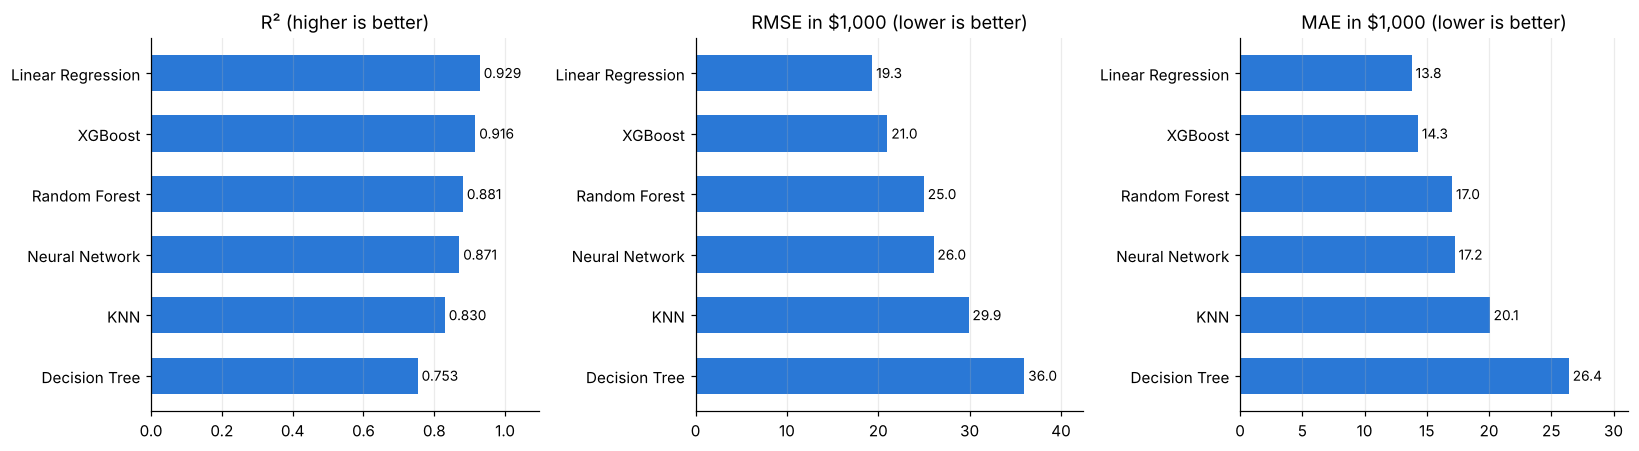

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
names = results_df["Model"][::-1]
spec = [("R2", "R² (higher is better)", 1, "{:.3f}"),
        ("RMSE", "RMSE in $1,000 (lower is better)", 1000, "{:.1f}"),
        ("MAE", "MAE in $1,000 (lower is better)", 1000, "{:.1f}")]
for ax, (metric, title, div, fmt) in zip(axes, spec):
    vals = results_df.set_index("Model").loc[names, metric] / div
    ax.barh(names, vals, color="#2a78d6", height=0.6)
    for i, v in enumerate(vals):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=9)
    ax.set_title(title); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, vals.max() * 1.18)
plt.tight_layout()
plt.savefig("images/metric_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

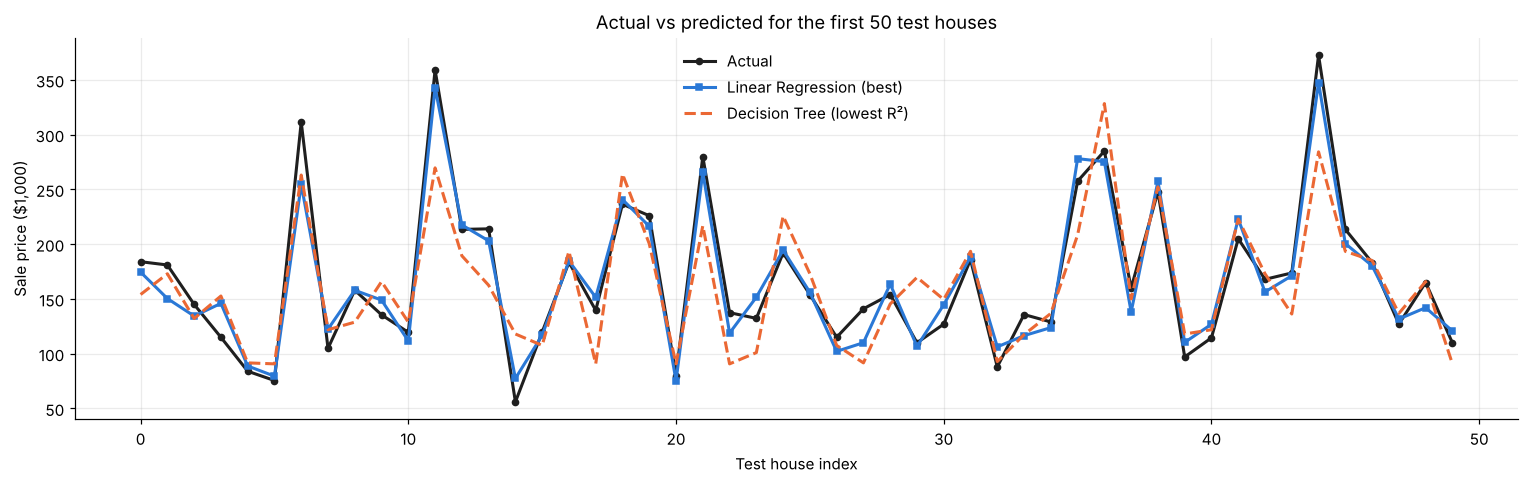

In [ ]:
best, worst = order[0], order[-1]
idx = np.arange(50)
plt.figure(figsize=(14, 4.5))
plt.plot(idx, y_test.values[:50] / 1000, color="#1f1f1f", lw=2, marker="o", ms=4, label="Actual")
plt.plot(idx, preds[best][:50] / 1000, color="#2a78d6", lw=2, marker="s", ms=4, label=f"{best} (best)")
plt.plot(idx, preds[worst][:50] / 1000, color="#eb6834", lw=2, ls="--", label=f"{worst} (lowest R²)")
plt.xlabel("Test house index"); plt.ylabel("Sale price ($1,000)")
plt.title("Actual vs predicted for the first 50 test houses")
plt.legend(frameon=False); plt.tight_layout()
plt.savefig("images/sample_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

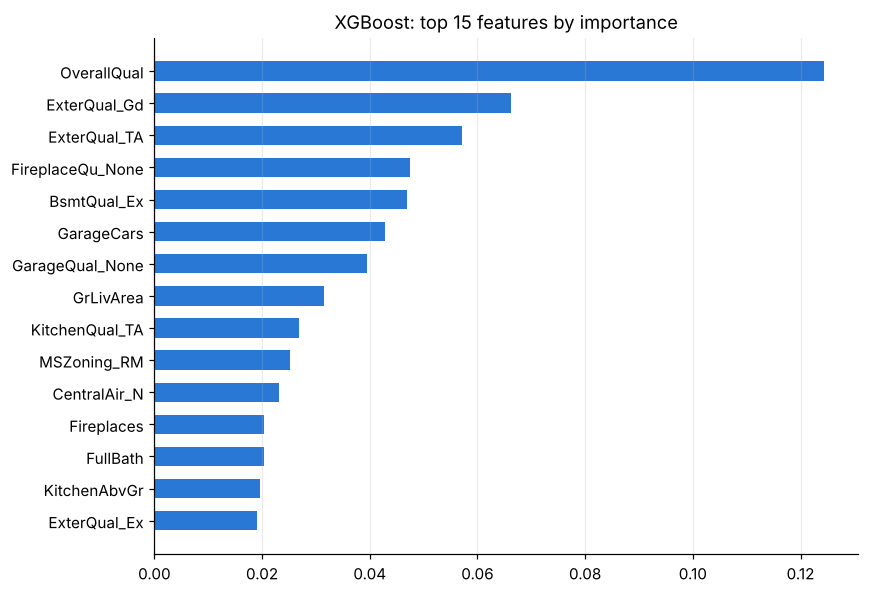

In [ ]:
# Top 15 features used by XGBoost (gain-based importance)
xgb_pipe = fitted["XGBoost"]
feat_names = xgb_pipe.named_steps["prep"].get_feature_names_out()
feat_names = [f.split("__", 1)[1] for f in feat_names]
imp = pd.Series(xgb_pipe.named_steps["model"].regressor_.feature_importances_, index=feat_names)
top = imp.sort_values().tail(15)
plt.figure(figsize=(8, 5.5))
plt.barh(top.index, top.values, color="#2a78d6", height=0.6)
plt.title("XGBoost: top 15 features by importance"); plt.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("images/xgb_feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Best model

In [ ]:
best_row = results_df.iloc[0]
print(f"Best model: {best_row['Model']}")
print(f"  R2   = {best_row['R2']:.4f}  (explains {best_row['R2']*100:.1f}% of the variation in sale price)")
print(f"  RMSE = ${best_row['RMSE']:,.0f}")
print(f"  MAE  = ${best_row['MAE']:,.0f}  (average absolute error per house)")
print(f"  Mean sale price in test set = ${y_test.mean():,.0f}")

Best model: Linear Regression
  R2   = 0.9287  (explains 92.9% of the variation in sale price)
  RMSE = $19,347
  MAE  = $13,787  (average absolute error per house)
  Mean sale price in test set = $175,425
